# Curated KG vs original KG: statistical comparison

NetMedGPT trained on the curated KG (`train.py --inference *_curated`) vs NetMedGPT trained on the original KG,
both evaluated on **the same curated test pairs**:
- original models: `data/new_analysis/curated_kg_training/original_on_curated_pairs_per_seed.csv`
  (original checkpoints scored on the curated test pairs with `compare_curated.ipynb`);
- curated models: `LP_test.csv` / `hit_precision_test.csv` of the curated training runs.

Statistics as in `other/statistical_significance_all_methods.ipynb`: two-sided paired t-test (pairing unit: seed),
bootstrap 95% CI of the mean paired difference (resampling unit: per-seed difference, 10,000 resamples), Cohen's d_z,
Holm correction within each split over all relations and metrics.
Output: `data/new_analysis/curated_kg_training/curated_vs_original_{stats.csv, bars.png/pdf}`. Reads only CSV files.

In [1]:
import os
if os.path.basename(os.getcwd()) == "curated_kg_training":
    os.chdir("../..")
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ORIGINAL = "data/new_analysis/curated_kg_training/original_on_curated_pairs_per_seed.csv"
CURATED = {"random_link_split": "data/result/curated_random/netmedgpt_random_link_split_curated_seed*",
           "zero_shot_split": "data/result/curated_zero_shot/netmedgpt_zero_shot_split_curated_seed*"}
METRICS = ["AUROC", "AUPRC", "Recall@100"]
OUT_DIR = "data/new_analysis/curated_kg_training"


# same functions as in other/statistical_significance_all_methods.ipynb
def bootstrap_ci(a, b, n_boot=10000, ci=95, seed=42):
    rng = np.random.default_rng(seed)
    diffs = a - b
    boot = np.array([rng.choice(diffs, size=len(diffs), replace=True).mean() for _ in range(n_boot)])
    return float(np.percentile(boot, (100 - ci) / 2)), float(np.percentile(boot, 100 - (100 - ci) / 2))

def holm(p_values):
    p = np.asarray(p_values, dtype=float)
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted

def cohens_dz(a, b):
    d = a - b
    sd = np.std(d, ddof=1)
    return float(np.mean(d) / sd) if sd > 0 else float("nan")

In [2]:
# ── Per-seed values of both models ───────────────────────────────────────────
orig = pd.read_csv(ORIGINAL).assign(model="original KG")
rows = []
for inference, pattern in CURATED.items():
    for run in sorted(glob.glob(pattern)):
        seed = int(run.rsplit("seed", 1)[1])
        lp = pd.read_csv(os.path.join(run, "LP_test.csv"), index_col=0)
        hp = pd.read_csv(os.path.join(run, "hit_precision_test.csv"), index_col=0)
        for rel in lp.index:
            rows.append({"inference": inference, "seed": seed, "relation": rel, "model": "curated KG",
                         "AUROC": lp.loc[rel, "auc"], "AUPRC": lp.loc[rel, "auprc"], "Recall@100": hp.loc[rel, "hit"]})
cur = pd.DataFrame(rows)
both = pd.concat([orig[cur.columns], cur], ignore_index=True)
print(cur.groupby("inference")["seed"].unique())

inference
random_link_split       [1, 2, 3, 4]
zero_shot_split      [1, 2, 3, 4, 5]
Name: seed, dtype: object


In [3]:
# ── Two-sided paired t-test per split / relation / metric, Holm within each split ─
res = []
for (inference, rel), g in both.groupby(["inference", "relation"], sort=False):
    for metric in METRICS:
        w = g.pivot_table(index="seed", columns="model", values=metric).dropna()
        if len(w) < 2:
            continue
        c, o = w["curated KG"].to_numpy(), w["original KG"].to_numpy()
        t, p = stats.ttest_rel(c, o)
        lo, hi = bootstrap_ci(c, o)
        res.append({"split": inference, "relation": rel, "metric": metric, "seeds": len(w),
                    "original_mean": o.mean(), "original_std": o.std(ddof=1),
                    "curated_mean": c.mean(), "curated_std": c.std(ddof=1),
                    "mean_diff": (c - o).mean(), "ci_low": lo, "ci_high": hi, "cohens_dz": cohens_dz(c, o),
                    "t_stat": t, "p_value": p})
res = pd.DataFrame(res)
for split, idx in res.groupby("split").groups.items():
    res.loc[idx, "p_holm"] = holm(res.loc[idx, "p_value"])
res["significant"] = res["p_holm"] < 0.05
res.to_csv(os.path.join(OUT_DIR, "curated_vs_original_stats.csv"), index=False)
res.round(4)

,split,relation,metric,seeds,original_mean,original_std,curated_mean,curated_std,mean_diff,ci_low,ci_high,cohens_dz,t_stat,p_value,p_holm,significant
0,random_link_split,indication,AUROC,4,0.8987,0.0234,0.8727,0.0229,-0.0260,-0.0325,-0.0189,-3.4751,-6.9501,0.0061,0.0550,False
1,random_link_split,indication,AUPRC,4,0.9282,0.0155,0.9126,0.0171,-0.0156,-0.0180,-0.0128,-5.2502,-10.5004,0.0018,0.0203,True
2,random_link_split,indication,Recall@100,4,0.7379,0.0298,0.7212,0.0335,-0.0167,-0.0435,0.0101,-0.5353,-1.0707,0.3628,1.0000,False
3,random_link_split,contraindication,AUROC,4,0.8972,0.0070,0.8875,0.0029,-0.0097,-0.0122,-0.0055,-2.2890,-4.5779,0.0196,0.1252,False
4,random_link_split,contraindication,AUPRC,4,0.9026,0.0083,0.8948,0.0038,-0.0078,-0.0114,-0.0029,-1.6050,-3.2099,0.0490,0.1958,False
5,random_link_split,contraindication,Recall@100,4,0.7259,0.0171,0.6985,0.0138,-0.0273,-0.0332,-0.0215,-3.8832,-7.7664,0.0044,0.0444,True
6,random_link_split,off-label use,AUROC,4,0.9431,0.0107,0.9346,0.0343,-0.0084,-0.0343,0.0084,-0.3257,-0.6514,0.5613,1.0000,False
7,random_link_split,off-label use,AUPRC,4,0.9534,0.0068,0.9487,0.0250,-0.0047,-0.0262,0.0103,-0.2158,-0.4316,0.6952,1.0000,False
8,random_link_split,off-label use,Recall@100,4,0.9238,0.0324,0.8559,0.0576,-0.0679,-0.0930,-0.0427,-2.2130,-4.4260,0.0214,0.1252,False
9,random_link_split,drug_protein,AUROC,4,0.9382,0.0054,0.9498,0.0043,0.0115,0.0100,0.0129,6.4473,12.8946,0.0010,0.0141,True


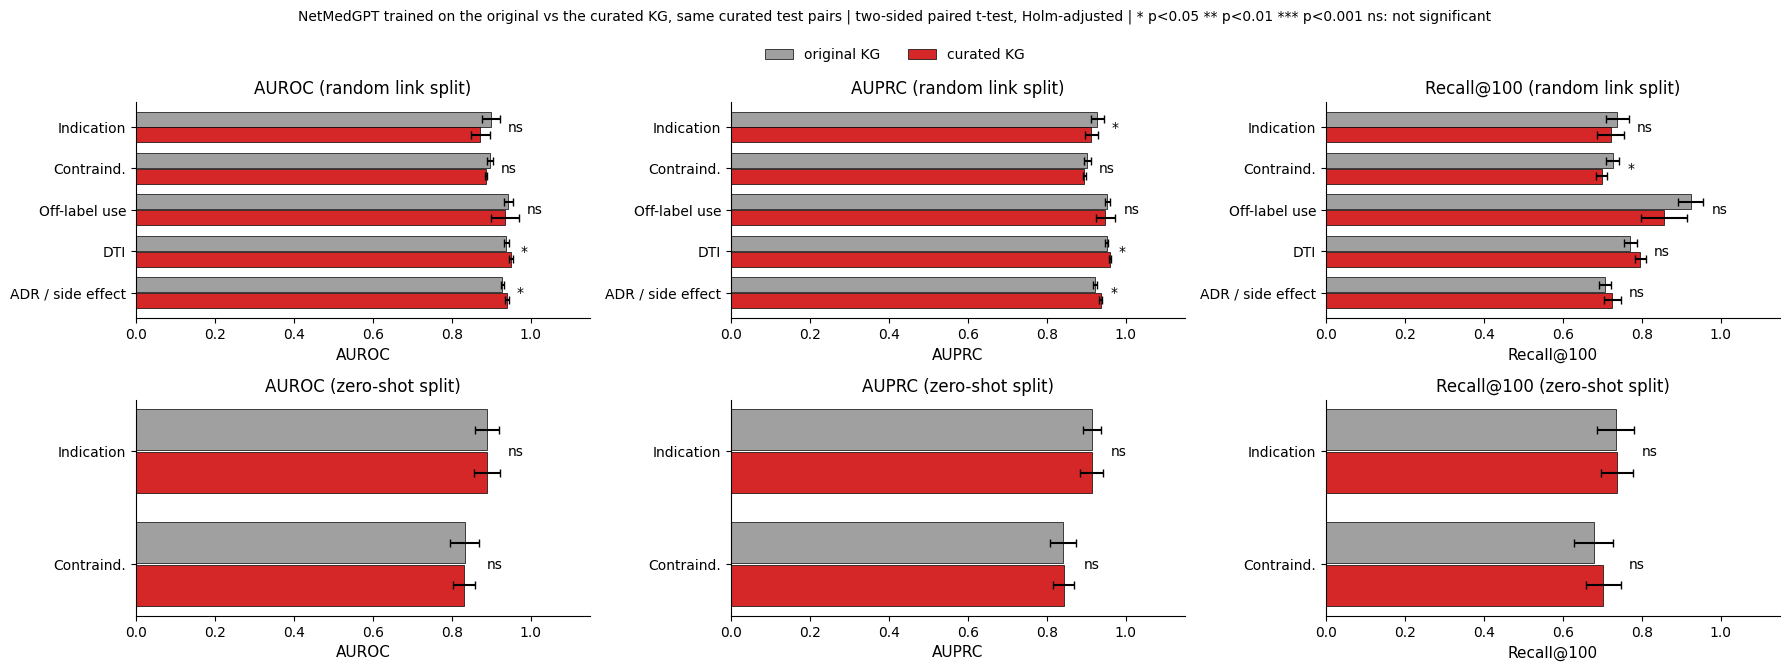

In [4]:
# ── Bars: original vs curated KG, mean +- SD, Holm-adjusted stars ─────────────
stars = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
LABELS = {"indication": "Indication", "contraindication": "Contraind.", "off-label use": "Off-label use",
          "drug_protein": "DTI", "drug_effect": "ADR / side effect"}
TITLES = {"random_link_split": "random link split", "zero_shot_split": "zero-shot split"}
splits = [s for s in CURATED if s in res["split"].unique()]
fig, axes = plt.subplots(len(splits), len(METRICS), figsize=(18, 3.2 * len(splits)), squeeze=False)
for i, split in enumerate(splits):
    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        r = res[(res["split"] == split) & (res["metric"] == metric)].reset_index(drop=True)
        y = np.arange(len(r))
        ax.barh(y - 0.19, r["original_mean"], 0.36, xerr=r["original_std"], color="#A0A0A0", capsize=3,
                edgecolor="black", linewidth=0.5, label="original KG")
        ax.barh(y + 0.19, r["curated_mean"], 0.36, xerr=r["curated_std"], color="#D62728", capsize=3,
                edgecolor="black", linewidth=0.5, label="curated KG")
        for k, row in r.iterrows():
            right = max(row["original_mean"] + row["original_std"], row["curated_mean"] + row["curated_std"])
            ax.text(right + 0.02, k, stars(row["p_holm"]), va="center", fontsize=10)
        ax.set_yticks(y)
        ax.set_yticklabels([LABELS[x] for x in r["relation"]], fontsize=10)
        ax.invert_yaxis()
        ax.set_xlim(0, 1.15)
        ax.set_xlabel(metric, fontsize=11)
        ax.set_title(f"{metric} ({TITLES[split]})", fontsize=12)
        ax.spines[["top", "right"]].set_visible(False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
fig.suptitle("NetMedGPT trained on the original vs the curated KG, same curated test pairs | two-sided paired t-test, "
             "Holm-adjusted | * p<0.05 ** p<0.01 *** p<0.001 ns: not significant", fontsize=10, y=1.04)
fig.tight_layout()
for ext in ["png", "pdf"]:
    fig.savefig(os.path.join(OUT_DIR, f"curated_vs_original_bars.{ext}"), dpi=300, bbox_inches="tight")
plt.show()